In [30]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("charts", exist_ok=True)

if not os.path.exists("SampleSuperstore.csv"):
    from google.colab import files
    files.upload()   # choose SampleSuperstore.csv

df = pd.read_csv("SampleSuperstore.csv")
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [31]:
print("Rows, columns (raw):", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

clean_df = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(clean_df))

clean_df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2)

Rows, columns (raw): (9994, 13)
Missing values: 0
Duplicate rows: 17
Rows after removing duplicates: 9977


,Sales,Quantity,Discount,Profit
count,9977.00,9977.00,9977.00,9977.00
mean,230.15,3.79,0.16,28.69
std,623.72,2.23,0.21,234.46
min,0.44,1.00,0.00,-6599.98
25%,17.30,2.00,0.00,1.73
50%,54.82,3.00,0.20,8.67
75%,209.97,5.00,0.20,29.37
max,22638.48,14.00,0.80,8399.98


In [32]:
%matplotlib inline
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

In [33]:
from IPython.display import display

def save_and_show(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    display(plt.gcf())   # force the chart to appear in the notebook
    plt.close()

def total_by(column, measure):
    return clean_df.groupby(column)[measure].sum().sort_values(ascending=False)

def bar_chart(series, title, xlabel, ylabel, color, filename, size=(8, 4)):
    plt.figure(figsize=size)
    series.sort_values().plot(kind="barh", color=color)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    save_and_show(filename)

In [34]:
total_sales = clean_df["Sales"].sum()
total_profit = clean_df["Profit"].sum()

print(f"Total Sales:   ${total_sales:,.2f}")
print(f"Total Profit:  ${total_profit:,.2f}")
print(f"Profit margin: {total_profit / total_sales:.1%}")

Total Sales:   $2,296,195.59
Total Profit:  $286,241.42
Profit margin: 12.5%


In [35]:
category_sales = total_by("Category", "Sales")
category_profit = total_by("Category", "Profit")

In [36]:
category_table = pd.DataFrame({"Sales": category_sales, "Profit": category_profit})
category_table["Margin"] = category_table["Profit"] / category_table["Sales"]
display(category_table.round(2).style.format({"Margin": "{:.1%}"}))

,Sales,Profit,Margin
Category,,,
Furniture,741306.310000,18421.810000,2.0%
Office Supplies,718735.240000,122364.660000,17.0%
Technology,836154.030000,145454.950000,17.0%


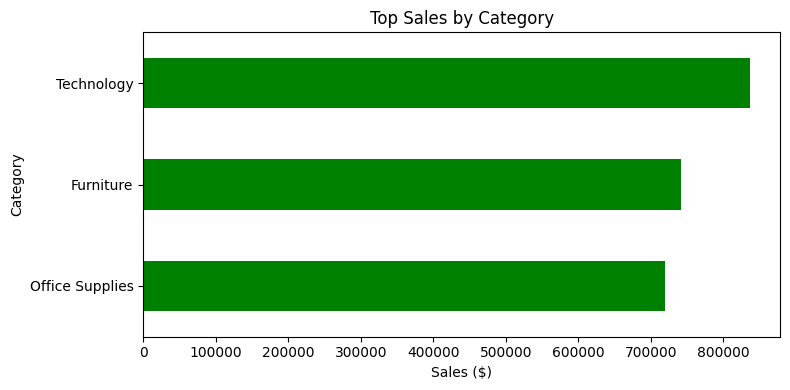

In [37]:
bar_chart(category_sales, "Top Sales by Category", "Sales ($)", "Category", "green", "sales_by_category")

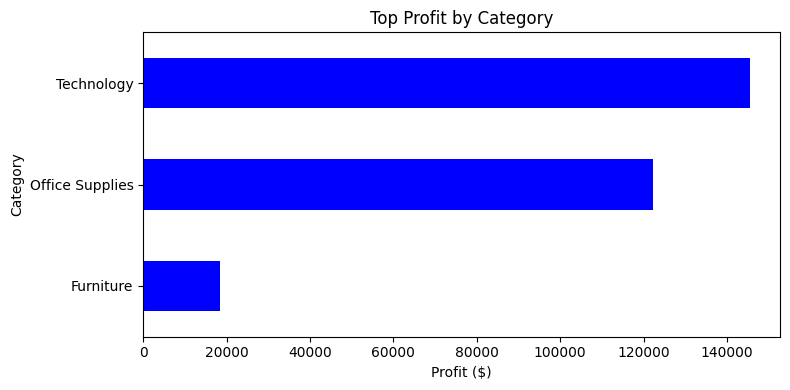

In [38]:
bar_chart(category_profit, "Top Profit by Category", "Profit ($)", "Category", "blue", "profit_by_category")

In [40]:
region_sales = total_by("Region", "Sales")
region_profit = total_by("Region", "Profit")

region_table = pd.DataFrame({
    "Sales": region_sales,
    "Sales share": region_sales / region_sales.sum(),
    "Profit": region_profit,
    "Profit share": region_profit / region_profit.sum(),
})
display(region_table.round(3).style.format({"Sales share": "{:.1%}", "Profit share": "{:.1%}"}))

,Sales,Sales share,Profit,Profit share
Region,,,,
Central,500782.853000,21.8%,39655.875000,13.9%
East,678435.196000,29.5%,91506.309000,32.0%
South,391721.905000,17.1%,46749.430000,16.3%
West,725255.636000,31.6%,108329.808000,37.8%


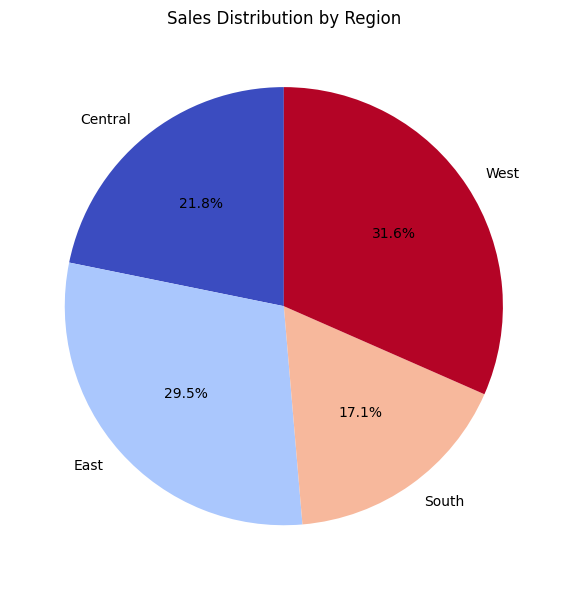

In [41]:
plt.figure(figsize=(6, 6))
region_sales.sort_index().plot.pie(autopct="%1.1f%%", startangle=90, cmap="coolwarm")
plt.title("Sales Distribution by Region")
plt.ylabel("")
save_and_show("sales_by_region")

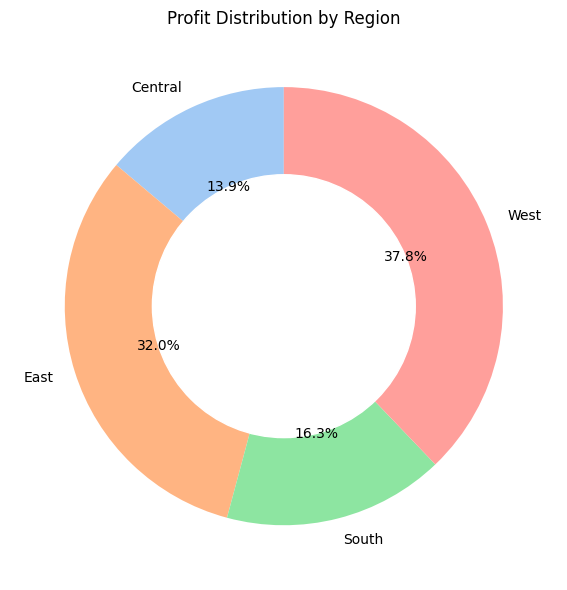

In [42]:
plt.figure(figsize=(6, 6))
region_profit.sort_index().plot.pie(autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
plt.gca().add_artist(plt.Circle((0, 0), 0.6, color="white"))
plt.title("Profit Distribution by Region")
plt.ylabel("")
save_and_show("profit_by_region")

In [44]:
segment_table = pd.DataFrame({"Sales": total_by("Segment", "Sales"),
                              "Profit": total_by("Segment", "Profit")})
display(segment_table.round(2))

,Sales,Profit
Segment,,
Consumer,1160832.77,134007.44
Corporate,706070.13,91954.98
Home Office,429292.68,60279.00


In [45]:
shipmode_table = pd.DataFrame({"Sales": total_by("Ship Mode", "Sales"),
                               "Profit": total_by("Ship Mode", "Profit")})
display(shipmode_table.round(2))

,Sales,Profit
Ship Mode,,
Standard Class,1357316.35,163969.23
Second Class,459177.05,57446.65
First Class,351380.47,48953.66
Same Day,128321.72,15871.89


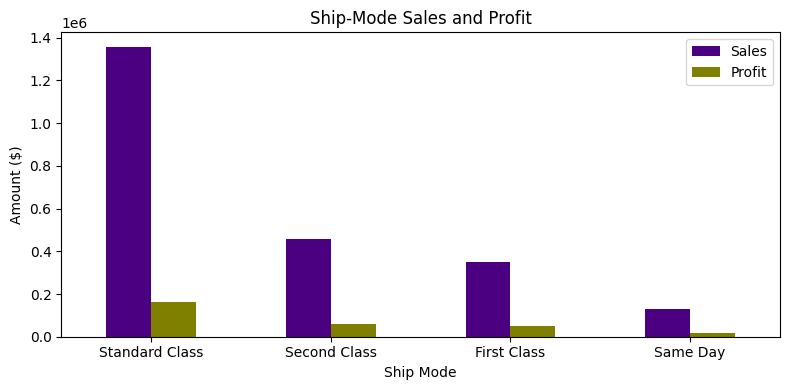

In [46]:
shipmode_table.plot(kind="bar", figsize=(8, 4), color=["#4B0082", "#808000"])
plt.title("Ship-Mode Sales and Profit")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
save_and_show("shipmode_sales_vs_profit")

In [47]:
sub_sales = total_by("Sub-Category", "Sales")
sub_profit = total_by("Sub-Category", "Profit")

display(sub_profit.round(2).to_frame("Profit"))

,Profit
Sub-Category,
Copiers,55617.82
Phones,44515.73
Accessories,41936.64
Paper,33944.24
Binders,30228.00
Chairs,26567.13
Storage,21278.83
Appliances,18138.01
Furnishings,13052.72


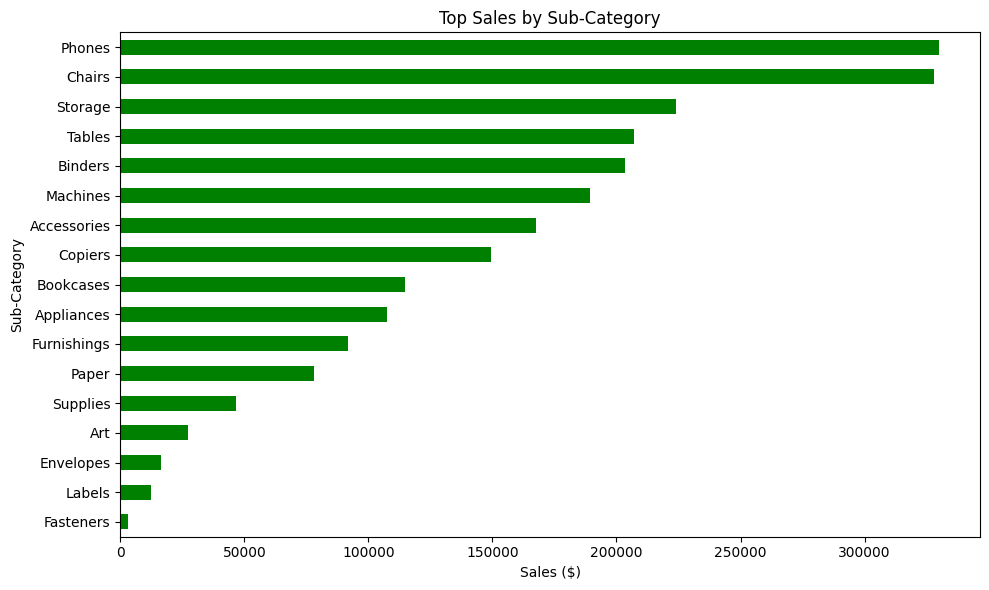

In [48]:
bar_chart(sub_sales, "Top Sales by Sub-Category", "Sales ($)", "Sub-Category",
          "green", "sales_by_subcategory", size=(10, 6))

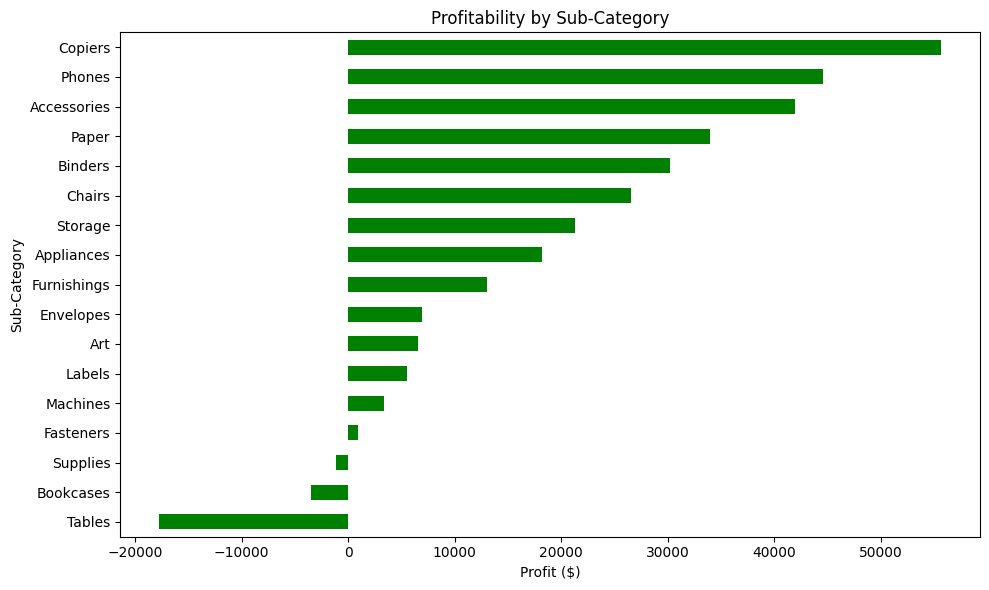

In [49]:
bar_chart(sub_profit, "Profitability by Sub-Category", "Profit ($)", "Sub-Category",
          "green", "profit_by_subcategory", size=(10, 6))

In [50]:
corr_matrix = clean_df[["Sales", "Profit", "Discount", "Quantity"]].corr()
display(corr_matrix.round(2))

,Sales,Profit,Discount,Quantity
Sales,1.00,0.48,-0.03,0.20
Profit,0.48,1.00,-0.22,0.07
Discount,-0.03,-0.22,1.00,0.01
Quantity,0.20,0.07,0.01,1.00


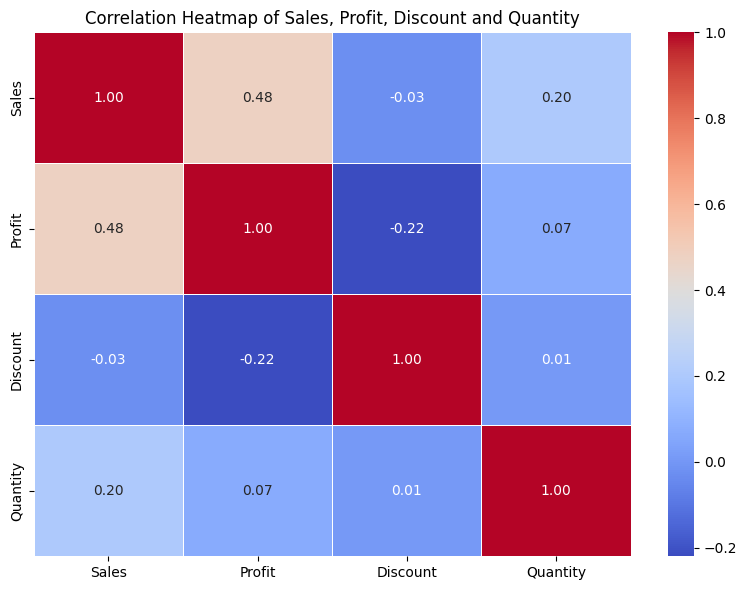

In [51]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Sales, Profit, Discount and Quantity")
save_and_show("correlation_heatmap")